In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


# Model Training & Evaluation: Gradient Boosting

**Team Member:** Mustafa

This notebook trains the ensemble boosting model (Gradient Boosting Classifier) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Validation set to avoid data leakage before final testing.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

In [2]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Gradient Boosting algorithm and evaluation metrics from scikit-learn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_val` / `y_val` for intermediate evaluation.

In [3]:
# -------------------------------------------------------------------------
# Load Processed Training and Validation Sets
# -------------------------------------------------------------------------
# Define the relative path to the preprocessed data directory
# Resolve the Data directory dynamically so the notebook runs whether the working
# directory is the project root or the notebooks/ folder (same logic as data_cleaning_merged)
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the validation subset
X_val = pd.read_csv(f"{base_path}processed_X_val.csv")

# Load the target variable (y) for the validation subset, isolating just the label column
y_val = pd.read_csv(f"{base_path}processed_y_val.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Validation set: {X_val.shape[0]:,} rows")

Training set: 14,000 rows
Validation set: 3,000 rows


In [4]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and validation partitions share an identical schema
assert list(X_train.columns) == list(X_val.columns), "Schema mismatch between train and validation sets!"
print("Schema check passed: train and validation columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_val: {int(X_val.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Val Count': y_val.value_counts().sort_index(),
    'Val (%)': (y_val.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_val == majority_class).mean()
print(f"Majority-class baseline accuracy on validation: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and validation columns are identical.
Missing values in X_train: 0 | X_val: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Val Count,Val (%)
Layoff_Risk,,,,
Low (0),4621,33.01,990,33.0
Medium (1),4621,33.01,990,33.0
High (2),4758,33.99,1020,34.0


Majority-class baseline accuracy on validation: 0.3400


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 14,000 training records. Evaluation is conducted solely against the 3,000 validation records. The test set remains completely unseen.

## 2. Model Initialization and Training

We use scikit-learn's `GradientBoostingClassifier` with its default hyperparameters (`n_estimators=100`, `learning_rate=0.1`, `max_depth=3`, `subsample=1.0`). Using defaults keeps this iteration a clean, untuned baseline so that any performance change relative to the previous demographic feature set can be attributed to the new features rather than to tuning.

In [5]:
# -------------------------------------------------------------------------
# Fit Gradient Boosting Classifier
# -------------------------------------------------------------------------
# We initialize the Gradient Boosting Classifier ensemble algorithm.
# We set random_state=42 to ensure the exact same trees are built every time 
# the code is run, enabling deterministic and reproducible results.
gbc = GradientBoostingClassifier(random_state=42)

# Fit the ensemble of decision trees strictly to the training partition.
gbc.fit(X_train, y_train)

print("Gradient Boosting training completed successfully!")

Gradient Boosting training completed successfully!


In [6]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Validation Accuracy
# A large gap between the two would indicate the ensemble is memorizing the
# training set rather than learning generalizable patterns.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gbc.predict(X_train))
val_acc = accuracy_score(y_val, gbc.predict(X_val))

print(f"Training Accuracy:   {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Generalization Gap (Train - Val): {train_acc - val_acc:+.4f}")

Training Accuracy:   0.7636
Validation Accuracy: 0.7463
Generalization Gap (Train - Val): +0.0173


## 3. Validation Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [7]:
# -------------------------------------------------------------------------
# Predict on Validation Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the validation subset
y_pred = gbc.predict(X_val)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_val, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Validation Accuracy: 0.7463

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.7869
  - Specificity (TNR):    0.9144
Medium (1):
  - Sensitivity (Recall): 0.6141
  - Specificity (TNR):    0.8149
High (2):
  - Sensitivity (Recall): 0.8353
  - Specificity (TNR):    0.8904

--- Macro Averages ---
Macro Sensitivity: 0.7454
Macro Specificity: 0.8733


In [8]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
# Precision = TP / (TP + FP) -> diagonal of the confusion matrix divided by predicted-class totals
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (VALIDATION SET) ---")
display(metrics_summary)

print(f"\nOverall Validation Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_val, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (VALIDATION SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.7869,0.9144,0.8191
Medium (1),0.6141,0.8149,0.6204
High (2),0.8353,0.8904,0.7970
Macro Average,0.7454,0.8732,0.7455



Overall Validation Accuracy: 0.7463

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.8191    0.7869    0.8027       990
  Medium (1)     0.6204    0.6141    0.6173       990
    High (2)     0.7970    0.8353    0.8157      1020

    accuracy                         0.7463      3000
   macro avg     0.7455    0.7454    0.7452      3000
weighted avg     0.7460    0.7463    0.7459      3000



> **Empirical Takeaway — Boosting Ensemble Performance:**
> With the workload- and automation-centric feature set, Gradient Boosting reaches a **validation accuracy of 74.63%** (vs. a 34.00% majority-class baseline and roughly 42–43% with the earlier demographic-only features). Macro sensitivity is **0.7454** and macro specificity is **0.8733**. The model separates the extreme tiers well: **High Risk** has the best recall (**0.8353**, F1 0.8157) and **Low Risk** has the best specificity (**0.9144**, F1 0.8027). **Medium Risk** remains the hardest tier (sensitivity **0.6141**, precision **0.6204**), which is expected because the middle class sits between two well-separated extremes and its feature distributions overlap with both. The train/validation gap is small (**76.36% vs. 74.63%, +1.73 pts**), indicating a well-generalized model with no material overfitting.

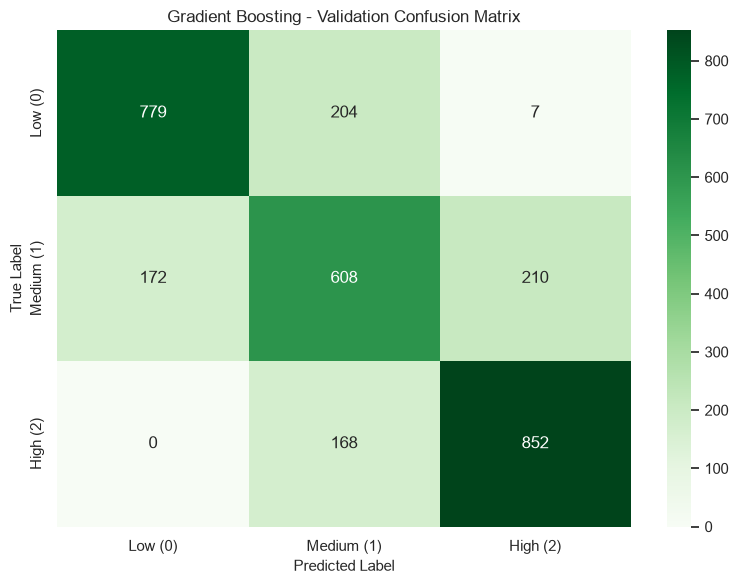

In [9]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gradient Boosting - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

## 4. Feature Importance

Gradient Boosting exposes impurity-based feature importances, aggregating each predictor's total contribution to loss reduction across all trees. This reveals which of the 11 predictors actually drive the model's layoff-risk predictions.

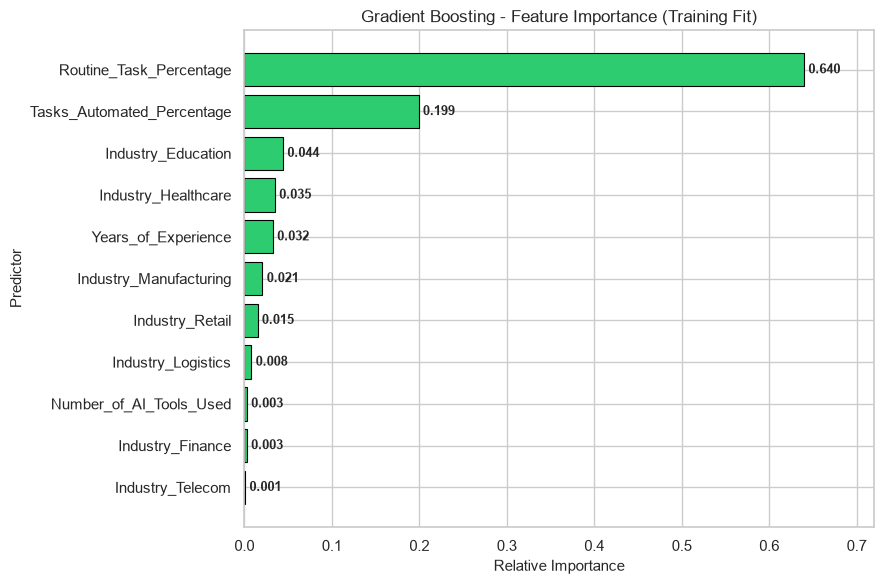

--- FEATURE IMPORTANCE TABLE (DESCENDING) ---


,Importance
Routine_Task_Percentage,0.6397
Tasks_Automated_Percentage,0.1991
Industry_Education,0.0441
Industry_Healthcare,0.0348
Years_of_Experience,0.0325
Industry_Manufacturing,0.0206
Industry_Retail,0.0150
Industry_Logistics,0.0079
Number_of_AI_Tools_Used,0.0027
Industry_Finance,0.0027


In [10]:
# -------------------------------------------------------------------------
# Feature Importance (Impurity-Based)
# Rank all 11 predictors by their relative contribution to the ensemble.
# -------------------------------------------------------------------------
importances = pd.Series(gbc.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
bars = plt.barh(importances.index, importances.values, color='#2ecc71', edgecolor='black', linewidth=0.8)

# Annotate each bar with its importance value
for bar, val in zip(bars, importances.values):
    plt.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va='center', fontsize=9.5, fontweight='bold')

plt.title("Gradient Boosting - Feature Importance (Training Fit)")
plt.xlabel("Relative Importance")
plt.ylabel("Predictor")
plt.xlim(0, importances.max() + 0.08)
plt.tight_layout()
plt.show()

print("--- FEATURE IMPORTANCE TABLE (DESCENDING) ---")
display(importances.sort_values(ascending=False).round(4).to_frame('Importance'))

> **Empirical Takeaway — What Drives the Predictions:**
> Importance is concentrated in two predictors: **`Routine_Task_Percentage` (0.6397)** and **`Tasks_Automated_Percentage` (0.1991)** together account for roughly **84%** of the ensemble's total importance, mirroring the strong tier separation seen in the EDA. Industry indicators contribute modestly (e.g., Education 0.0441, Healthcare 0.0348, Manufacturing 0.0206), and `Years_of_Experience` adds a small effect (0.0325). Notably, `Number_of_AI_Tools_Used` receives very low importance (0.0027) despite its strong marginal relationship with risk in the EDA; this is explained by its correlation with the two dominant predictors (r = 0.66 with routine tasks, r = 0.59 with tasks automated), so it contributes little *additional* information once those are in the model. Caveat: impurity-based importance can be shared arbitrarily among correlated predictors, so these values should be read as indicative rather than causal.